# IND320 Project work, part 2: Data Sources

Haakon Risbråthe, autumn 2026

This notebook gets reservoir data from the NVE API and cross-border electricity
flows from ENTSO-E. The flows are stored in Cassandra with Spark and then in
MongoDB, which the Streamlit app reads from.

- [Assignment](https://nmbu.instructure.com/courses/14185/assignments/58732)
- GitHub repository, branch `prosjekt-del-2`: <https://github.com/Haakon5555/ind320-haakon5555/tree/prosjekt-del-2>
- Streamlit app: <https://ind320-haakon5555-bfhbsiaysptxoqxqkwr8o4.streamlit.app/>
- [Part 1 notebook](prosjekt_del_1.ipynb)

The notebook automatically uses the ENTSO-E API when a token is configured.
Without a token it uses the preserved website exports. The selected source
is printed in sections 0 and 2.


## 0. Environment and access

Use **Python 3 (ipykernel)** from
`/Users/ola/miniconda3/envs/data_analysis/bin/python`.
The local database dependencies are listed in `requirements-local.txt`.
The Streamlit deployment keeps its existing `requirements.txt`.

Add the token to the existing `.streamlit/secrets.toml` file:

```toml
ENTSOE_API_TOKEN = ""
```

Paste the token between the quotation marks and keep the existing MongoDB entry.
Save the file, then choose **Restart Kernel and Run All Cells**. Do not paste
the token into the notebook. The first cell starts Cassandra and waits for it
to become healthy. Docker Desktop must be running. To stop Cassandra later,
run `docker compose stop` in this notebook's folder. The database persists in the Docker volume
`ind320_cassandra_data`. Stopping the container does not remove the data.

Local setup: PySpark **3.5.1**, Spark-Cassandra connector **3.5.1** (Scala 2.12),
Cassandra **4.1.12**, cassandra-driver **3.30.1**, PyMongo **4.19.0**, and the
existing Java **17**. Cassandra is reachable at **127.0.0.1:9042**, with local
datacenter `datacenter1`. The connector downloads to Spark's normal Ivy cache
on first use. The connection cells configure Java/Python for this process.
No global shell configuration is needed.

See the [course installation guide](https://khliland.github.io/IND320/installation/) and
[connector compatibility](https://github.com/apache/cassandra-spark-connector#version-compatibility).

MongoDB uses a free Atlas M0 cluster. Put `MONGODB_URI` in the environment or
in `.streamlit/secrets.toml`, which is excluded from Git. On Streamlit Cloud,
copy it to the app's Secrets settings. Never put the connection string in a
code cell or notebook output. The local connection was tested with a ping.

The token can also be set as the environment variable `ENTSOE_API_TOKEN`,
which takes priority over the local secrets file. No additional packages
are needed for the API loader. API access was requested on 20 October 2026.
The analysis uses the last two complete calendar years, 2024 and 2025.


In [1]:
# Load local credentials without displaying their contents.
import importlib.util
import os
import sys
import subprocess
import tomllib
from pathlib import Path
from importlib.metadata import version

print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
packages = {
    "pandas": "pandas", "matplotlib": "matplotlib", "requests": "requests",
    "streamlit": "streamlit", "pyspark": "pyspark",
    "cassandra": "cassandra-driver", "pymongo": "pymongo",
}
for module, distribution in packages.items():
    if importlib.util.find_spec(module) is None:
        raise RuntimeError(f"Missing {distribution}. Select the data_analysis kernel.")
    print(f"{distribution}: {version(distribution)}")
if not Path("compose.yaml").is_file():
    raise RuntimeError("Open and run this notebook from its project folder.")
secrets = {}
secret_file = Path(".streamlit/secrets.toml")
if secret_file.is_file():
    try:
        with secret_file.open("rb") as handle:
            secrets = tomllib.load(handle)
    except tomllib.TOMLDecodeError:
        raise RuntimeError("Check the quotation marks in the local secrets file.") from None
entsoe_token = (os.environ.get("ENTSOE_API_TOKEN") or secrets.get("ENTSOE_API_TOKEN", "")).strip()
mongo_uri = os.environ.get("MONGODB_URI") or secrets.get("MONGODB_URI")
flow_source = "ENTSO-E REST API" if entsoe_token else "ENTSO-E website CSV exports"
print("Transfer source:", flow_source)
if not mongo_uri:
    raise RuntimeError("Configure MONGODB_URI in the local secrets file.")

# Check Atlas access before downloading or updating any data.
from pymongo import MongoClient
from pymongo.errors import PyMongoError
try:
    with MongoClient(mongo_uri, serverSelectionTimeoutMS=15000) as client:
        client.admin.command("ping")
except PyMongoError:
    raise RuntimeError("MongoDB is unavailable. Check Atlas access and MONGODB_URI.") from None
print("MongoDB connection: OK")

# Reuse the existing container and data volume, waiting until Cassandra is ready.
try:
    setup = subprocess.run(
        ["docker", "compose", "up", "-d", "--wait", "--wait-timeout", "180"],
        capture_output=True, text=True, timeout=210,
    )
except (FileNotFoundError, subprocess.TimeoutExpired):
    raise RuntimeError("Start Docker Desktop and rerun this cell.") from None
if setup.returncode:
    raise RuntimeError("Cassandra did not become ready. Check Docker Desktop and docker compose ps.")
print("Cassandra: healthy")


Python: 3.11.13
Interpreter: /Users/ola/miniconda3/envs/data_analysis/bin/python
pandas: 2.3.2
matplotlib: 3.10.5
requests: 2.32.5
streamlit: 1.64.0
pyspark: 3.5.1
cassandra-driver: 3.30.1
pymongo: 4.19.0
Transfer source: ENTSO-E website CSV exports


MongoDB connection: OK


Cassandra: healthy


## 1. NVE API and reservoir data

The notebook and app now get data directly from NVE with `requests.get`, as in
[the course API examples](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/3_APIs/2_REST.ipynb).
No account or API key is needed. The response is JSON with the same eleven
columns used in part 1. The CSV file from part 1 has been removed from the repository.

[API documentation](https://biapi.nve.no/magasinstatistikk/swagger/index.html) and
[API schema](https://biapi.nve.no/magasinstatistikk/swagger/v1/swagger.json) describe
four endpoints. `HentOffentligData` gives the history, `HentOffentligDataSisteUke`
gives the latest week, `HentOffentligDataMinMaxMedian` gives reference statistics,
and `HentOmråder` describes the areas.

**Period selection.** The documented endpoints have no date or area parameters.
The code downloads the history once and selects the period locally. The
Streamlit slider therefore controls the displayed period, not the network
request. This is a limitation compared with the assignment update of 12 October.
The same issue was raised in the
[course Padlet](https://padlet.com/khliland/ind320-autumn-2026-imipysat5k87jzxh).
The teacher acknowledged the issue and asked whether anyone had found a way
to filter in the API.


In [2]:
# Download the history and check HTTP errors before reading the JSON.
import pandas as pd
import matplotlib.pyplot as plt
import requests

base_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/"
response = requests.get(base_url + "HentOffentligData", timeout=30)
response.raise_for_status()
reservoirs_raw = pd.DataFrame(response.json())
print(f"Downloaded {len(reservoirs_raw):,} rows and {len(reservoirs_raw.columns)} columns.")

# Make a copy of the table with English column names.
reservoirs = reservoirs_raw.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "filling_ratio",
    "kapasitet_TWh": "capacity_twh",
    "fylling_TWh": "stored_energy_twh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "previous_week_filling_ratio",
    "endring_fyllingsgrad": "change_in_filling_ratio"
})


# Use measurement dates for the time axis, not publication dates.
reservoirs["date"] = pd.to_datetime(reservoirs["date"])
reservoirs = reservoirs.sort_values(["date", "area_type", "area_number"]).reset_index(drop=True)
assert not reservoirs.duplicated(["date", "area_type", "area_number"]).any()
iso = reservoirs["date"].dt.isocalendar()
assert iso["year"].eq(reservoirs["iso_year"]).all()
assert iso["week"].eq(reservoirs["iso_week"]).all()
display(reservoirs.isna().sum().rename("Missing values"))
display(reservoirs.groupby(["area_type", "area_number"]).agg(
    weeks=("date", "size"), first=("date", "min"), last=("date", "max")
))

# Compare the area catalogue with the area codes actually returned in the data.
response = requests.get(base_url + "HentOmråder", timeout=30)
response.raise_for_status()
areas = pd.DataFrame([
    area for catalogue in response.json()
    for group in catalogue.values() for area in group
])
available = set(zip(reservoirs["area_type"], reservoirs["area_number"]))
areas["has_measurements"] = [
    (kind, number) in available for kind, number in zip(areas["omrType"], areas["omrnr"])
]
display(areas[["omrType", "omrnr", "navn", "beskrivelse", "has_measurements"]])


Downloaded 14,922 rows and 11 columns.


date                           0
area_type                      0
area_number                    0
iso_year                       0
iso_week                       0
filling_ratio                  0
capacity_twh                   0
stored_energy_twh              0
next_publication_date          0
previous_week_filling_ratio    0
change_in_filling_ratio        0
Name: Missing values, dtype: int64

weeks      first       last
area_type area_number                             
EL        1             1658 1995-01-08 2026-10-11
          2             1658 1995-01-08 2026-10-11
          3             1658 1995-01-08 2026-10-11
          4             1658 1995-01-08 2026-10-11
          5             1658 1995-01-08 2026-10-11
NO        0             1658 1995-01-08 2026-10-11
VASS      1             1658 1995-01-08 2026-10-11
          2             1658 1995-01-08 2026-10-11
          3             1658 1995-01-08 2026-10-11

,omrType,omrnr,navn,beskrivelse,has_measurements
0,NO,0,Norge,Hele landet,True
1,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlande...,True
2,EL,2,NO 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,True
3,EL,3,NO 3,Midt-Norge. Omfatter nordre og vestlige del av...,True
4,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og No...,True
5,EL,5,NO 5,Vest-Norge. Omfatter midtre del av Vestland op...,True
6,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",True
7,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.,True
8,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",True
9,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.,False


### 1.1 Areas, time and data quality

The response on 20 October has 14,922 rows, from 8 January 1995 to
11 October 2026. There are 1,658 observations for each of nine areas.
No fields are null and no area has duplicate measurement dates.

- `NO 0` is Norway as a whole.
- `EL 1` to `EL 5` are electricity price areas, commonly called NO1 to NO5.
  They cover southeastern, southwestern, central, northern and western Norway.
- The measurements contain `VASS 1`, `VASS 2` and `VASS 3`.
  However, the current area catalogue describes four water regions and includes
  `VASS 4`, which has no measurements in this response. We retain the reported
  codes and do not reinterpret the historical VASS 3 series as the new definition.

These are overlapping geographical groupings. Norway is already the total,
so it must not be added to the regional values.

The measurement dates are Sundays. Their ISO years and weeks agree with
Pandas' ISO calendar. ISO year can differ from calendar year around New Year,
so we keep both the actual date and the reported ISO fields. The next publication
date is a different field. Its year 0001 value is a placeholder, found in
11,322 rows, and is displayed as missing publication information.

The five measurements are filling ratio, capacity, stored energy, previous
week's filling ratio and weekly change. Ratios are fractions. Multiplying by
100 gives percent for filling levels and percentage points for weekly change.
Capacity and stored energy are in TWh. NVE explains the relationship between
[stored energy and filling level](https://www.nve.no/energi/analyser-og-statistikk/om-magasinstatistikken/).

### 1.2 Recreate the reservoir plots from part 1

The next cells reuse the plotting code from part 1. The five individual plots
show all reported areas. The combined plots use Norway to keep them readable.
Dates and labels are shown in a table because they are not measurements.


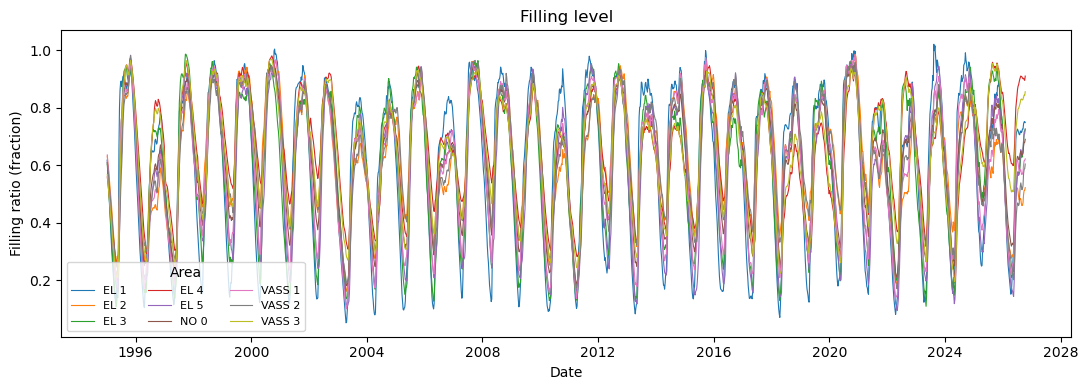

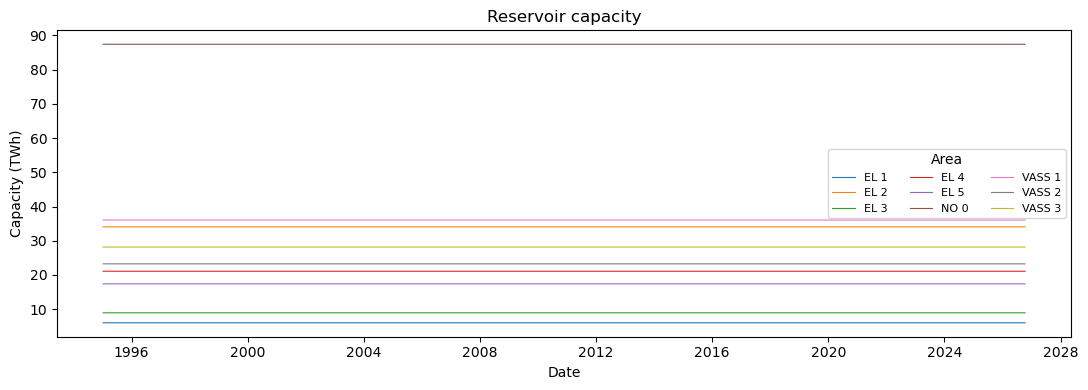

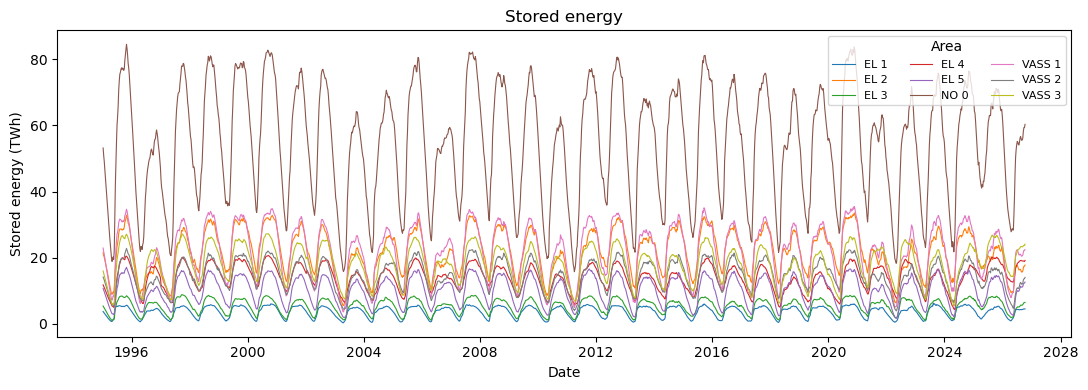

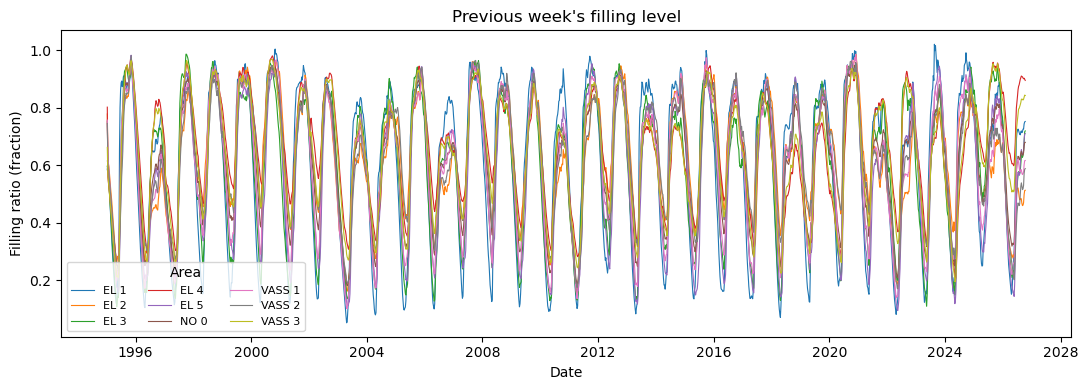

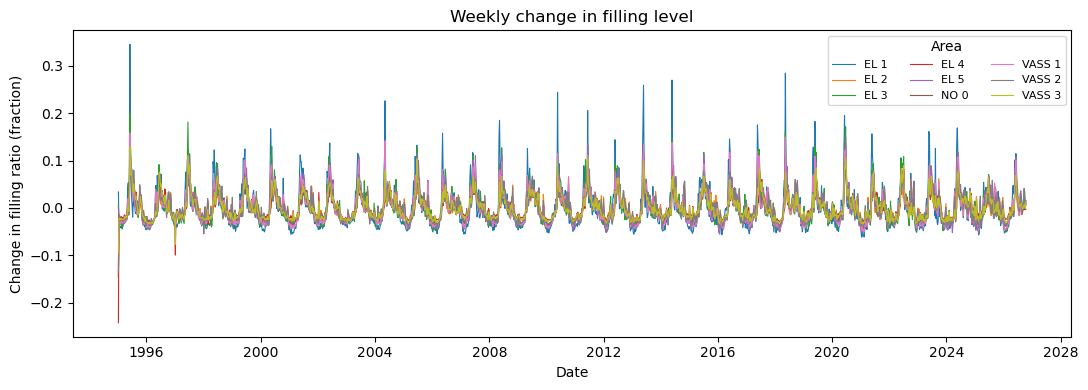

In [3]:
# Make a copy where the dates are real dates, sorted from oldest to newest.
plot_data = reservoirs.copy()
plot_data["date"] = pd.to_datetime(plot_data["date"])
plot_data = plot_data.sort_values("date")

# Title and y-axis label for each of the five measurement columns.
measurement_labels = {
    "filling_ratio": ("Filling level", "Filling ratio (fraction)"),
    "capacity_twh": ("Reservoir capacity", "Capacity (TWh)"),
    "stored_energy_twh": ("Stored energy", "Stored energy (TWh)"),
    "previous_week_filling_ratio": ("Previous week's filling level", "Filling ratio (fraction)"),
    "change_in_filling_ratio": (
        "Weekly change in filling level", "Change in filling ratio (fraction)"
    ),
}
measurement_columns = list(measurement_labels)

# One figure per column.
for column, (title, unit_label) in measurement_labels.items():
    fig, ax = plt.subplots(figsize=(11, 4))
    # One line per area. groupby keeps the areas apart.
    for (kind, number), area in plot_data.groupby(["area_type", "area_number"]):
        ax.plot(area["date"], area[column], label=f"{kind} {number}", linewidth=0.8)
    ax.set(title=title, xlabel="Date", ylabel=unit_label)
    ax.legend(title="Area", ncol=3, fontsize=8)
    fig.tight_layout()
    plt.show()

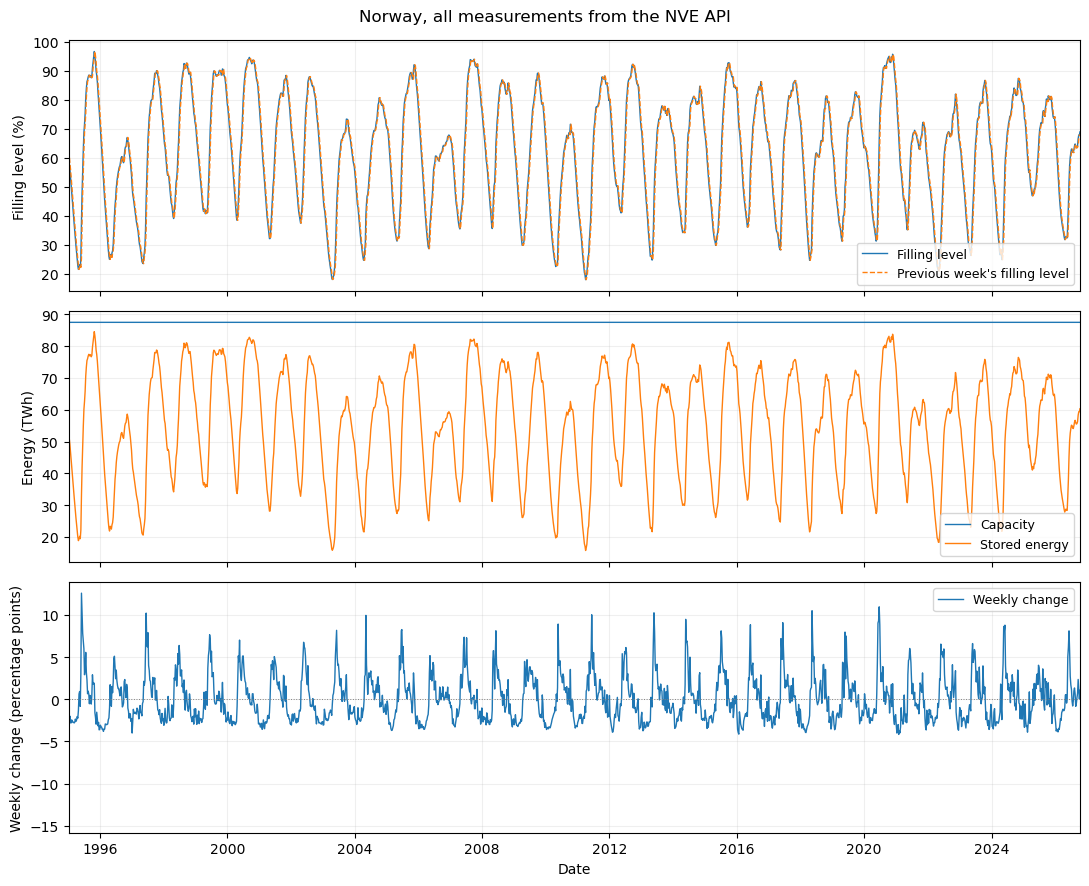

,date,area_type,area_number,iso_year,iso_week,next_publication_date
5,1995-01-08,NO,0,1995,1,Not reported
14,1995-01-15,NO,0,1995,2,Not reported
23,1995-01-22,NO,0,1995,3,Not reported
32,1995-01-29,NO,0,1995,4,Not reported
41,1995-02-05,NO,0,1995,5,Not reported


In [4]:
# Use only the rows for Norway (NO 0).
norway = plot_data.loc[
    (plot_data["area_type"] == "NO") & (plot_data["area_number"] == 0)
].copy()

# Three groups, one per panel: column, label and what to multiply with.
# Fractions are multiplied by 100 to get percent and percentage points.
groups = [
    ([("filling_ratio", "Filling level", 100),
      ("previous_week_filling_ratio", "Previous week's filling level", 100)], "Filling level (%)"),
    ([("capacity_twh", "Capacity", 1),
      ("stored_energy_twh", "Stored energy", 1)], "Energy (TWh)"),
    ([("change_in_filling_ratio", "Weekly change", 100)], "Weekly change (percentage points)"),
]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
fig.suptitle("Norway, all measurements from the NVE API")
for ax, (series, unit_label) in zip(axes, groups):
    for column, label, multiplier in series:
        ax.plot(
            norway["date"], norway[column] * multiplier, label=label,
            # Dashed line for last week's level, since it lies close to this week's.
            linewidth=1, linestyle="--" if column == "previous_week_filling_ratio" else "-",
        )
    ax.set_ylabel(unit_label)
    ax.legend(loc="best", fontsize=9)
    ax.grid(alpha=0.2)
# Zero line in the bottom panel, to see if the level went up or down.
axes[-1].axhline(0, color="gray", linewidth=0.7, linestyle=":")
axes[-1].set_xlabel("Date")
axes[-1].set_xlim(norway["date"].min(), norway["date"].max())
fig.tight_layout()
plt.show()

# Show the first rows of the six columns with dates and labels.
metadata_columns = [column for column in norway.columns if column not in measurement_columns]
metadata_preview = norway[metadata_columns].head().copy()
# Year 0001 is a placeholder in the file, so there is no real date.
metadata_preview["next_publication_date"] = metadata_preview["next_publication_date"].replace(
    "0001-01-01T00:00:00", "Not reported"
)
display(metadata_preview)

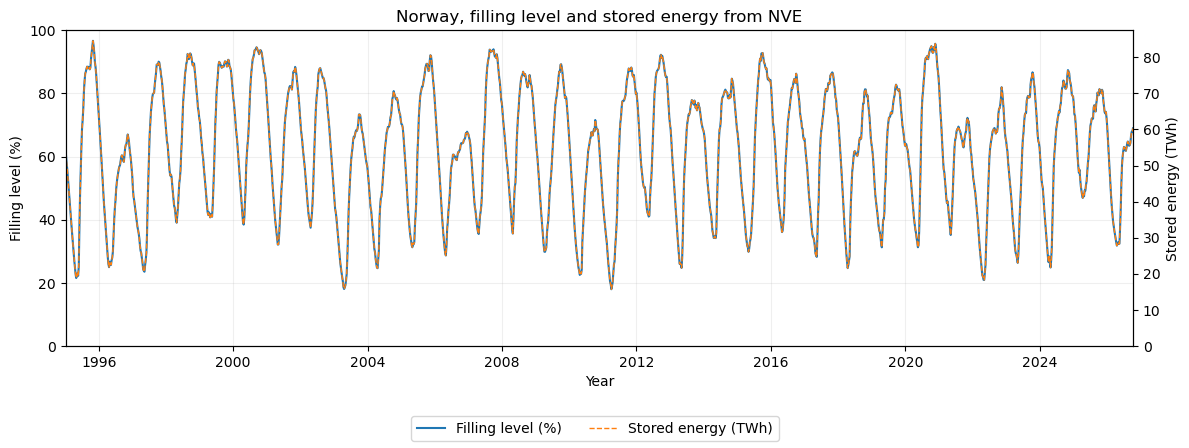

In [5]:
# Two y-axes in the same plot: percent on the left and TWh on the right.
fig, ax_left = plt.subplots(figsize=(12, 4.5))
ax_right = ax_left.twinx()
filling_line, = ax_left.plot(
    norway["date"], norway["filling_ratio"] * 100,
    color="tab:blue", linewidth=1.5, label="Filling level (%)"
)
energy_line, = ax_right.plot(
    norway["date"], norway["stored_energy_twh"],
    color="tab:orange", linestyle="--", linewidth=1, label="Stored energy (TWh)"
)

# The right axis stops at the capacity, so 100% and full capacity are at the same height.
ax_left.set_ylim(0, 100)
ax_right.set_ylim(0, norway["capacity_twh"].iloc[0])
ax_left.set_ylabel("Filling level (%)")
ax_right.set_ylabel("Stored energy (TWh)")
ax_left.set_xlabel("Year")
ax_left.set_xlim(norway["date"].min(), norway["date"].max())
ax_left.set_title("Norway, filling level and stored energy from NVE")
ax_left.grid(alpha=0.2)

# One legend for both lines, below the figure.
fig.legend(handles=[filling_line, energy_line], loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.09, 1, 1))
plt.show()

In [6]:
# Summarise the values used in the interpretation rather than copying old figures.
monthly = norway.groupby(norway["date"].dt.month)["filling_ratio"].mean() * 100
print("Mean filling level by calendar month (%)")
display(monthly.round(1))
print("Norway capacity (TWh)", norway["capacity_twh"].unique())
print("Largest weekly rise (percentage points)", 100 * norway["change_in_filling_ratio"].max())
print("First reported weekly change (percentage points)",
      100 * norway["change_in_filling_ratio"].iloc[0])
print("Year 0001 placeholders", reservoirs["next_publication_date"].str.startswith("0001").sum())
display(reservoirs.loc[reservoirs["filling_ratio"] > 1,
    ["date", "area_type", "area_number", "filling_ratio"]])


Mean filling level by calendar month (%)


date
1     62.9
2     51.4
3     40.7
4     33.0
5     37.1
6     56.7
7     71.8
8     77.8
9     80.4
10    82.1
11    80.6
12    72.5
Name: filling_ratio, dtype: float64

Norway capacity (TWh) [87.43758]
Largest weekly rise (percentage points) 12.577379
First reported weekly change (percentage points) -14.464319
Year 0001 placeholders 11322


,date,area_type,area_number,filling_ratio
2718,2000-10-22,EL,1,1.003412
13428,2023-08-13,EL,1,1.020072
13446,2023-08-27,EL,1,1.014961


### 1.3 Interpretation

The plots retain the seasonal pattern from part 1. Reservoir levels generally
fall through winter and rise again during spring and summer. Capacity is
constant in this API response. This does not mean the real capacity has always
been constant. The national figure is about 87.44 TWh, and stored energy follows
the filling ratio on the corresponding energy scale.

The download has five more weeks per area than the CSV used in part 1.
It also has three filling ratios above 1, all for EL 1, compared with two in the
old file. The additional observation is 22 October 2000. This shows that a new
API response can revise historical values as well as add recent weeks.
The values are retained as reported, without clipping them at 100%.
The unusually large first weekly change is also retained. These observations
should be checked before using the data for modelling.


## 2. ENTSO-E cross-border data

The source is [Cross-Border Physical Flows, TR 12.1.G](https://transparency.entsoe.eu/transmission/physicalFlows).
With `ENTSOE_API_TOKEN` configured, `entsoe_loader.py` requests physical flows
(document type A11) for nine international connections, in both directions.
The period is the last two complete calendar years, 2024 and 2025.
Each request covers one connection, direction and year, giving 36 requests.

The loader preserves valid XML responses as `data/entsoe/api_*.xml` and reuses
them on later runs. Existing source files are not overwritten. The filename
follows each row through Cassandra and MongoDB. Neither the token nor the
request URL is saved. An API error stops execution before the database writes.

The parser checks area codes, direction, MW units, finite nonnegative values,
and full UTC coverage. A03 curves describe values that stay constant until
the next change within the same period. A01 curves require every position.
Gaps and overlapping intervals stop execution. Complete 15 or 30 minute
intervals are combined into hourly mean MW using their durations, preserving
energy. The XML files retain the original resolution.

Without a token, the notebook uses the eight unchanged annual CSV exports
for NO1 to NO4 in `data/entsoe`. These were downloaded on 20 October 2026
with the website timezone set to UTC. This mode does not meet the API retrieval
requirement. The output below identifies which source was used.

Only flows with exactly one Norwegian endpoint are retained. The connections
are NO1 with SE3, NO2 with DE-LU, DK1, GB and NL, NO3 with SE2, and NO4 with
FI, SE1 and SE2. These are area-to-area flows, not individual cable measurements.
`Out Area` sends electricity and `In Area` receives it.

References: [API reference](https://documenter.getpostman.com/view/7009892/2s93JtP3F6),
[area codes](https://transparencyplatform.zendesk.com/hc/en-us/articles/15885757676308-Area-List-with-Energy-Identification-Code-EIC),
[response and direction](https://transparencyplatform.zendesk.com/hc/en-us/articles/15727773247124-Query-Response),
[curve types](https://transparencyplatform.zendesk.com/hc/en-us/articles/30262342482961-CurveType-A01-vs-CurveType-A03).


In [7]:
# Select API automatically when the token is present. Errors never trigger CSV fallback.
from entsoe_loader import load_api_flows, CONNECTIONS

if entsoe_token:
    flows = load_api_flows(entsoe_token)
else:
    from pathlib import Path
    import hashlib

    source_dir = Path("data/entsoe")
    frames = []
    source_summary = []
    for area in ("no1", "no2", "no3", "no4"):
        for year in (2024, 2025):
            path = source_dir / f"entsoe_{area}_{year}.csv"
            frame = pd.read_csv(path, dtype=str)
            frame["source_file"] = path.name
            frames.append(frame)
            source_summary.append({"File": path.name, "Rows": len(frame),
                                   "SHA256 prefix": hashlib.sha256(path.read_bytes()).hexdigest()[:12]})
    raw_flows = pd.concat(frames, ignore_index=True)
    display(pd.DataFrame(source_summary))

    # Keep international transfers only, with Norway at exactly one endpoint.
    raw_flows["out_area"] = raw_flows["Out Area"].str.removeprefix("BZN|")
    raw_flows["in_area"] = raw_flows["In Area"].str.removeprefix("BZN|")
    out_is_norway = raw_flows["out_area"].str.startswith("NO")
    in_is_norway = raw_flows["in_area"].str.startswith("NO")
    flows = raw_flows.loc[out_is_norway ^ in_is_norway].copy()

    # The export view was set to UTC. Parse both ends of each interval explicitly.
    interval = flows["MTU"].str.split(" - ", expand=True)
    flows["start_utc"] = pd.to_datetime(interval[0], format="%d/%m/%Y %H:%M:%S", utc=True)
    flows["end_utc"] = pd.to_datetime(interval[1], format="%d/%m/%Y %H:%M:%S", utc=True)
    flows["power_mw"] = pd.to_numeric(flows["Physical Flow (MW)"], errors="coerce")
    flows["year"] = flows["start_utc"].dt.year
    flows["direction"] = "Import"
    exports = flows["out_area"].str.startswith("NO")
    flows.loc[exports, "direction"] = "Export"
    flows["norway_area"] = flows["out_area"].where(exports, flows["in_area"])
    flows["foreign_area"] = flows["in_area"].where(exports, flows["out_area"])
    flows["connection"] = flows["norway_area"] + " / " + flows["foreign_area"]
    flows["duration_hours"] = (flows["end_utc"] - flows["start_utc"]).dt.total_seconds() / 3600


print("Transfer source:", flow_source)
# Require every connection, year and direction before writing to the databases.
expected_groups = {
    (f"{norway} / {foreign}", year, direction)
    for norway, foreign in CONNECTIONS
    for year in (2024, 2025) for direction in ("Import", "Export")
}
assert set(flows.groupby(["connection", "year", "direction"]).groups) == expected_groups
# Do not replace missing values with zero or silently remove duplicate intervals.
assert flows["power_mw"].notna().all(), "Missing or non-numeric cross-border values"
assert flows["power_mw"].ge(0).all(), "Unexpected negative directional flow"
assert not flows.duplicated(["connection", "direction", "start_utc"]).any()
assert flows["duration_hours"].eq(1).all(), "Recheck coverage for a new resolution"
coverage_rows = []
for (connection, year, direction), group in flows.groupby(["connection", "year", "direction"]):
    expected = pd.date_range(
        f"{year}-01-01", f"{year + 1}-01-01", freq="h", inclusive="left", tz="UTC"
    )
    actual = pd.DatetimeIndex(group["start_utc"].sort_values())
    assert actual.equals(expected), f"Incomplete coverage for {connection}, {year}, {direction}"
    coverage_rows.append({"Connection": connection, "Year": year,
                          "Direction": direction, "Hours": len(actual)})
coverage = pd.DataFrame(coverage_rows).pivot(
    index=["Connection", "Year"], columns="Direction", values="Hours"
)
display(coverage)
print(f"Checked {len(flows):,} cross-border observations with complete hourly coverage.")


,File,Rows,SHA256 prefix
0,entsoe_no1_2024.csv,87840,dc8685a30968
1,entsoe_no1_2025.csv,87600,18b0366eb1de
2,entsoe_no2_2024.csv,122976,1a4b97c7d032
3,entsoe_no2_2025.csv,122640,6b051f92c9b3
4,entsoe_no3_2024.csv,70272,f5a4f7628dd9
5,entsoe_no3_2025.csv,70080,4e1111cdebc9
6,entsoe_no4_2024.csv,70272,420c001cc3e9
7,entsoe_no4_2025.csv,70080,d069b098e07a


Transfer source: ENTSO-E website CSV exports


Direction         Export  Import
Connection  Year                
NO1 / SE3   2024    8784    8784
            2025    8760    8760
NO2 / DE-LU 2024    8784    8784
            2025    8760    8760
NO2 / DK1   2024    8784    8784
            2025    8760    8760
NO2 / GB    2024    8784    8784
            2025    8760    8760
NO2 / NL    2024    8784    8784
            2025    8760    8760
NO3 / SE2   2024    8784    8784
            2025    8760    8760
NO4 / FI    2024    8784    8784
            2025    8760    8760
NO4 / SE1   2024    8784    8784
            2025    8760    8760
NO4 / SE2   2024    8784    8784
            2025    8760    8760

Checked 315,792 cross-border observations with complete hourly coverage.


## 3. Cassandra and Spark

### 3.1 Connection and storage

The code follows the course examples for
[Cassandra](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/2_Databases/3_Cassandra.ipynb) and
[Spark](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/2_Databases/4_Spark.ipynb).
The Cassandra driver creates the table, while Spark writes and reads the data.

The partition key is `(connection, year)`. The clustering columns are direction
and start time. Together they uniquely identify an hourly directional flow.
Running the notebook again updates the same keys rather than appending duplicate
measurements. The source filename and endpoints are retained for traceability.
The existing table name `physical_flows_exports` is retained. A complete API
run updates the same hourly keys for 2024 and 2025, including source filenames.


In [8]:
# Configure Java and Python for this notebook process before starting Spark.
import subprocess
from cassandra.cluster import Cluster
from cassandra.policies import DCAwareRoundRobinPolicy
from pyspark.sql import SparkSession

if sys.platform == "darwin" and not os.environ.get("JAVA_HOME"):
    os.environ["JAVA_HOME"] = subprocess.check_output(
        ["/usr/libexec/java_home", "-v", "17"], text=True
    ).strip()
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

spark = (
    SparkSession.builder.master("local[2]")
    .appName("IND320 part 2")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.ui.enabled", "false")
    .config("spark.sql.shuffle.partitions", "2")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.jars.repositories", "https://repo.maven.apache.org/maven2")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.cassandra.connection.localDC", "datacenter1")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

https://repo.maven.apache.org/maven2 added as a remote repository with the name: repo-1
Ivy Default Cache set to: /Users/ola/.ivy2/cache
The jars for the packages stored in: /Users/ola/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-43d3f4a1-7fcf-4fb8-9364-48a56a409121;1.0
	confs: [default]


:: loading settings :: url = jar:file:/Users/ola/miniconda3/envs/data_analysis/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central


	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central


	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central


	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central


	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect;2.12.19 in central
:: resolution report :: resolve 1267ms :: artifacts dl 36ms
	:: modules in use:
	com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 from central in [default]
	com.datastax.oss#native-protocol;1.5.1 from central in [default]
	com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 from central in [default]
	com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 from central in [default]
	com.thoughtworks.paranamer#paranamer;2.8 from central in [default]
	com.typesafe#config;1.4.1 from central in [default]
	io.dropwizard.metrics#metrics-core;4.1.18 from central in [default]
	org.apache.cassandra#java-driver-core-shaded;4.18.1 from central in [default]
	org.apache.cassandra#java-driver-mapper-runtime;4.18.1 from central in [default]
	org.apache.cassandra#java-driver-query-builder;4.18.1 from central in [default]
	org.apache.commons#commons-lang3;3.10 from c

26/10/20 21:05:38 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark version: 3.5.1


In [9]:
# Create the real-data table. Existing records are kept and updated by primary key.
cluster = Cluster(
    ["127.0.0.1"], port=9042,
    load_balancing_policy=DCAwareRoundRobinPolicy(local_dc="datacenter1"),
    protocol_version=4,
)
try:
    session = cluster.connect()
    session.execute(
        "CREATE KEYSPACE IF NOT EXISTS ind320 WITH replication = "
        "{'class': 'NetworkTopologyStrategy', 'datacenter1': 1}"
    )
    session.execute("""
        CREATE TABLE IF NOT EXISTS ind320.physical_flows_exports (
            connection text, year int, direction text, start_utc timestamp,
            end_utc timestamp, out_area text, in_area text, power_mw double,
            source_file text,
            PRIMARY KEY ((connection, year), direction, start_utc)
        )
    """)
finally:
    cluster.shutdown()

# Pass timestamps as epoch milliseconds to avoid local daylight-saving conversion.
storage_columns = ["connection", "year", "direction", "start_utc", "end_utc",
                   "out_area", "in_area", "power_mw", "source_file"]
storage = flows[storage_columns].copy()
spark_input = storage.copy()
for column in ("start_utc", "end_utc"):
    spark_input[column] = spark_input[column].astype("int64") // 1_000_000
schema = ("connection string, year int, direction string, start_utc long, "
          "end_utc long, out_area string, in_area string, power_mw double, source_file string")
spark_flows = spark.createDataFrame(spark_input, schema=schema)
from pyspark.sql import functions as F
for column in ("start_utc", "end_utc"):
    spark_flows = spark_flows.withColumn(column, F.expr(f"timestamp_millis({column})"))
assert spark_flows.count() == len(storage)
(spark_flows.write.format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="physical_flows_exports")
    .mode("append").save())
print(f"Spark wrote {len(storage):,} records to Cassandra.")


/var/folders/zc/3nkzqyjd28l1320jz8q762200000gn/T/ipykernel_79170/1601894192.py:2: DeprecationWarning: Legacy execution parameters will be removed in 4.0. Consider using execution profiles.
  cluster = Cluster(


Spark wrote 315,792 records to Cassandra.


### 3.2 Extract relevant columns with Spark

Spark reads the table back, filters the two years and selects the fields needed
for the plots and MongoDB. Energy is calculated as average MW multiplied by
interval duration in hours. MWh divided by one million gives TWh.
The full read-back is compared with the source records before using the result.


UTC timestamps cross the Python and Spark boundary as epoch milliseconds.
This avoids interpreting repeated local times during the autumn clock change.
Both timestamps and measured values must match exactly after the round trip.


In [10]:
# Read from Cassandra, then perform the selection and energy calculation in Spark.
from pyspark.sql import functions as F

stored = (spark.read.format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="physical_flows_exports").load())
selected = (stored.filter(F.col("year").isin(2024, 2025))
    .select(*storage_columns)
    .withColumn("duration_hours",
                (F.col("end_utc").cast("long") - F.col("start_utc").cast("long")) / 3600)
    .withColumn("energy_mwh", F.col("power_mw") * F.col("duration_hours"))
    .withColumn("month", F.month("start_utc")))
# Keep UTC instants through the Spark to pandas conversion as well.
for column in ("start_utc", "end_utc"):
    selected = selected.withColumn(column, F.expr(f"unix_millis({column})"))
curated = selected.toPandas()
for column in ("start_utc", "end_utc"):
    curated[column] = pd.to_datetime(curated[column], unit="ms", utc=True)

# Compare every stored field, including every measured value, with the input.
keys = ["connection", "year", "direction", "start_utc"]
pd.testing.assert_frame_equal(
    storage.sort_values(keys).reset_index(drop=True),
    curated[storage_columns].sort_values(keys).reset_index(drop=True),
    check_dtype=False, check_exact=True,
)
curated = curated.sort_values(keys).reset_index(drop=True)
print(f"Verified all {len(curated):,} Cassandra records against the source.")
display(curated[["connection", "year", "direction", "start_utc", "power_mw", "energy_mwh"]].head())


Verified all 315,792 Cassandra records against the source.


,connection,year,direction,start_utc,power_mw,energy_mwh
0,NO1 / SE3,2024,Export,2024-01-01 00:00:00+00:00,0.0,0.0
1,NO1 / SE3,2024,Export,2024-01-01 01:00:00+00:00,0.0,0.0
2,NO1 / SE3,2024,Export,2024-01-01 02:00:00+00:00,0.0,0.0
3,NO1 / SE3,2024,Export,2024-01-01 03:00:00+00:00,0.0,0.0
4,NO1 / SE3,2024,Export,2024-01-01 04:00:00+00:00,0.0,0.0


## 4. Transfer plots

### 4.1 Annual import and export

The selected connection is NO2 with the Netherlands, and the year is 2025.
The pie chart shows physical energy transferred in each direction. The task
uses the word "production", but cross-border flows measure transfers, not
production at power plants. These are gross directional totals, not net export.
All intervals are present, including genuine zero flows.


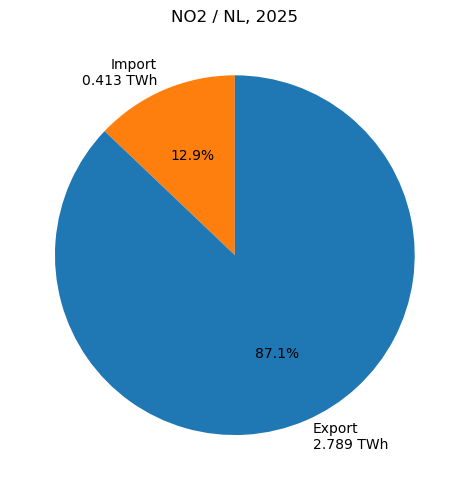

direction
Import    0.41266
Export    2.78876
Net export 2.376 TWh


In [11]:
# All figures use the data read back through Spark, not the original source table.
chosen_connection = "NO2 / NL"
chosen_year = 2025
chosen = curated.loc[
    curated["connection"].eq(chosen_connection) & curated["year"].eq(chosen_year)
]
annual_twh = (chosen.groupby("direction")["energy_mwh"].sum()
              .reindex(["Import", "Export"]) / 1_000_000)
fig, ax = plt.subplots(figsize=(6, 5))
labels = [f"{direction}\n{value:.3f} TWh" for direction, value in annual_twh.items()]
ax.pie(annual_twh, labels=labels, autopct="%.1f%%",
       colors=["tab:orange", "tab:blue"], startangle=90)
ax.set_title(f"{chosen_connection}, {chosen_year}")
fig.tight_layout()
plt.show()
print(annual_twh.round(6).to_string())
print(f"Net export {annual_twh['Export'] - annual_twh['Import']:.3f} TWh")


### 4.2 January line plot

The same connection is shown for January 2025. The task asks for separate lines
for each connection and direction. With one chosen connection, this gives one line
for import and one for export. Power in MW is on the vertical axis and UTC time
is on the horizontal axis.
The plots use hourly mean MW. API intervals shorter than one hour are
combined using their durations, while the original XML is preserved. A zero is retained as
zero. It is not used as a replacement for a missing observation.


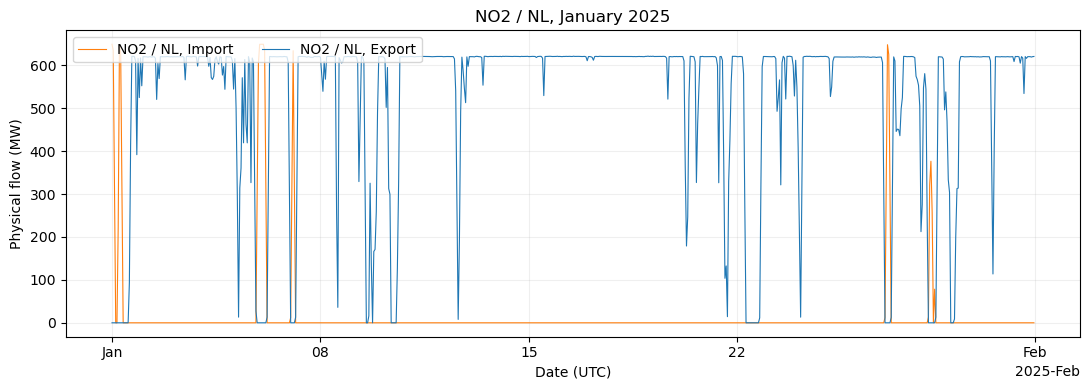

,count,mean,max
direction,,,
Export,744,527.30,621.40
Import,744,16.24,649.09


In [12]:
# January contains 744 hourly values per direction for this connection.
import matplotlib.dates as mdates

january = chosen.loc[chosen["month"].eq(1)]
fig, ax = plt.subplots(figsize=(11, 4))
for direction, color in [("Import", "tab:orange"), ("Export", "tab:blue")]:
    series = january.loc[january["direction"].eq(direction)].sort_values("start_utc")
    ax.plot(series["start_utc"], series["power_mw"],
            label=f"{chosen_connection}, {direction}", color=color, linewidth=0.8)
ax.set(title=f"{chosen_connection}, January {chosen_year}",
       xlabel="Date (UTC)", ylabel="Physical flow (MW)")
locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", ncol=2)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
display(january.groupby("direction")["power_mw"].agg(["count", "mean", "max"]).round(2))


In [13]:
# Recalculate the interpretation when the data source changes.
from IPython.display import Markdown, display

export = annual_twh["Export"]
imports = annual_twh["Import"]
share = 100 * export / (export + imports) if export + imports else 0
means = january.groupby("direction")["power_mw"].mean()
counts = january.groupby("direction").size()
display(Markdown(
    f"### 4.3 Interpretation\n\nSource: **{flow_source}**. "
    f"For {chosen_connection} in {chosen_year}, annual export is {export:.3f} TWh "
    f"and import is {imports:.3f} TWh. Export accounts for {share:.1f} percent "
    f"of the directional total. Net export is {export - imports:.3f} TWh. "
    f"In January, mean export is {means['Export']:.2f} MW and mean import is "
    f"{means['Import']:.2f} MW, with {counts['Export']:,} export and "
    f"{counts['Import']:,} import observations. "
    "These results describe this connection and year, not all Norwegian trade."
))


### 4.3 Interpretation

Source: **ENTSO-E website CSV exports**. For NO2 / NL in 2025, annual export is 2.789 TWh and import is 0.413 TWh. Export accounts for 87.1 percent of the directional total. Net export is 2.376 TWh. In January, mean export is 527.30 MW and mean import is 16.24 MW, with 744 export and 744 import observations. These results describe this connection and year, not all Norwegian trade.

## 5. MongoDB

The connection follows the course's
[MongoDB example](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/2_Databases/5_MongoDB.ipynb).
The Atlas database is `ind320` and the collection is `physical_flow_months`.
Each document contains one connection and calendar month, with an array of
hourly records for both directions. The records retain UTC start and end times,
power in MW, interval energy in MWh and source filename. Nothing is averaged
or discarded when the Spark-extracted rows are grouped into documents.

This produces 216 monthly documents holding 315,792 observations. Grouping
reduces the number of write operations on the free cluster and matches the
month selection in the app. The document ID combines connection, year and month.
Upserts replace the same document on repeated runs. A unique index on those
three fields supports the queries. The code checks document size against
MongoDB's 16 MiB limit before uploading.

The full collection is then read back and expanded into rows. Every field and
value is compared with the Spark extraction. Credentials remain outside the
notebook and its output. [Atlas free cluster limits](https://www.mongodb.com/docs/atlas/reference/free-shared-limitations/).


In [14]:
# Read the local connection without printing it or raw connection exceptions.
import tomllib
from pymongo import MongoClient, ReplaceOne
from pymongo.errors import PyMongoError
from bson import BSON

# Group for storage only. Keep every hourly value and both directions.
value_columns = ["direction", "start_utc", "end_utc", "power_mw", "energy_mwh", "source_file"]
mongo_columns = ["connection", "year", "month"] + value_columns
documents = []
for (connection, year, month), group in curated.groupby(["connection", "year", "month"]):
    values = group[value_columns].to_dict("records")
    for value in values:
        for column in ("start_utc", "end_utc"):
            value[column] = value[column].to_pydatetime()
    documents.append({
        "_id": f"{connection}|{year}|{month:02d}", "connection": connection,
        "year": int(year), "month": int(month), "values": values,
        "source_method": flow_source,
    })
assert len(documents) == 9 * 2 * 12
assert sum(len(document["values"]) for document in documents) == len(curated)
max_size = max(len(BSON.encode(document)) for document in documents)
assert max_size < 16 * 1024 * 1024

try:
    with MongoClient(mongo_uri, tz_aware=True, serverSelectionTimeoutMS=15000) as client:
        client.admin.command("ping")
        collection = client["ind320"]["physical_flow_months"]
        collection.bulk_write(
            [ReplaceOne({"_id": row["_id"]}, row, upsert=True) for row in documents],
            ordered=False,
        )
        collection.create_index([("connection", 1), ("year", 1), ("month", 1)], unique=True)
        stored_documents = list(collection.find({}))
        assert collection.count_documents({}) == len(documents)
except PyMongoError as error:
    raise RuntimeError(f"MongoDB operation failed ({type(error).__name__}).") from None

# Expand the monthly arrays and compare all rows with the Spark extraction.
uploaded = pd.DataFrame([
    {"connection": document["connection"], "year": document["year"],
     "month": document["month"], **value}
    for document in stored_documents for value in document["values"]
])
for column in ("start_utc", "end_utc"):
    uploaded[column] = pd.to_datetime(uploaded[column], utc=True)
pd.testing.assert_frame_equal(
    curated[mongo_columns].sort_values(keys).reset_index(drop=True),
    uploaded[mongo_columns].sort_values(keys).reset_index(drop=True),
    check_dtype=False, check_exact=True,
)
print(f"Verified {len(uploaded):,} hourly observations "
      f"in {len(stored_documents)} MongoDB documents.")
print(f"Largest document {max_size / 1024:.1f} KiB.")
display(uploaded.groupby(["connection", "year"]).size().unstack("year"))


Verified 315,792 hourly observations in 216 MongoDB documents.
Largest document 208.3 KiB.


year,2024,2025
connection,,
NO1 / SE3,17568,17520
NO2 / DE-LU,17568,17520
NO2 / DK1,17568,17520
NO2 / GB,17568,17520
NO2 / NL,17568,17520
NO3 / SE2,17568,17520
NO4 / FI,17568,17520
NO4 / SE1,17568,17520
NO4 / SE2,17568,17520


## 6. Streamlit implementation

`data_loader.py` requests the NVE history, renames the columns and sorts dates.
The response is cached for one hour and reused by both pages. HTTP failures,
missing columns and duplicate observations stop the page with an error message.

The sidebar has an area radio control and a month range slider. Both end months
are included. Their choices are shared by Data and Plots. The initial view
covers the last twelve available calendar months. As explained in section 1,
the API does not document date filtering, so the slider filters after download.

Data has one row per reported area number, with five `LineChartColumn` trends.
An expander shows the weekly values and dates. Plots keeps the column menu from
part 1 and draws separate lines for the area numbers. The combined plot groups
the measurements by unit. Dates and labels remain in a table.

The NVE cells were run in a fresh kernel and produced seven figures, which
were visually checked. Local Streamlit checks covered all area types, the
first month, the full period, shared selections, individual and combined plots,
and an API timeout. Both pages reused one HTTP request.

Transfers is page four, and About has moved to page five. The new page queries
MongoDB directly. The left column has connection radio buttons, a year selector
and a pie chart. The right column has month pills and a line plot. Empty month
selection displays a message. Non-adjacent months are separated by gaps in the
plot, rather than joined across months that were not selected.

The MongoDB client is cached with `st.cache_resource`, and query results are
cached for ten minutes. MongoDB unwinds the monthly arrays and aggregates annual energy totals. The
line plot query retrieves only the chosen months and required fields. An expander
explains the source and preparation. The MongoDB connection string is kept
outside Git. The online app reads it from the Streamlit Cloud secrets settings.

All five pages were checked locally with live data sources. The transfer checks
compared MongoDB annual totals directly with the original ENTSO-E file, checked
all 18 connection/year choices, leap-year February, January together with March,
empty month selection and a change of connection. The original CSV run completed all 14 code cells, and all 315,792 observations
matched after both database stages. The notebook now also includes automatic
source selection and a calculated interpretation. A live API run still requires
an activated token.


## 7. Work log

This part builds on the reservoir app from part 1. I kept the same repository and made a new notebook for the analysis. The main change is that the notebook and app now get reservoir data directly from NVE instead of reading the old CSV file.

**Jupyter Notebook.** The first step was to check the new data and recreate the plots from part 1. There are now several areas to compare, so the plots need to show which area each line belongs to. The checks also found some filling levels above 100 percent. These were kept as reported rather than changed just to make the data look cleaner.

The electricity transfer analysis uses ENTSO-E website exports while the API key is pending.

**Databases.** Setting up Cassandra, Spark and MongoDB was a new part of the work. Spark stores the transfer data in Cassandra and reads it back for the analysis. The prepared data then goes to MongoDB, where the app can read it. The values were compared after both steps to check that nothing had changed or disappeared.

**Streamlit.** The Data and Plots pages now share the area and period selections, so it is easier to move between them. A new Transfers page shows electricity going into and out of Norway. It has a pie chart for a whole year and a line plot for selected months. The page was also checked with no months selected and with months that are not next to each other.

**Problems.** The NVE API does not provide date parameters, so the slider filters the data after it has been downloaded. Another problem was handling timestamps around the autumn clock change. This was fixed before the database results were used. Keeping the notebook and app consistent took some work, especially making sure the dates, units and import and export directions meant the same thing in both.


## 8. AI usage

I used AI in much the same way as described in part 1. I work in the Codex
desktop app, where I go through several rounds of writing, code reviews and
changes. I follow the work in the notebook and code files and discuss what
can be improved along the way. The aim is to answer the assignment as well
as possible and understand the solution.


## 9. Screencast

The link to the screencast is given as a comment to the Canvas submission.


## 10. Close the local Spark session

Run this after finishing the notebook. Cassandra remains available in Docker.
To work with Spark again, rerun the connection cell in section 3.

In [15]:
# Release Spark's local Java process when the notebook work is finished.
spark.stop()
print("Spark stopped; Cassandra data remain in the Docker volume.")

Spark stopped; Cassandra data remain in the Docker volume.
